# Parameter Variation Plots

In [ ]:
# %% [markdown]
# # Parameter Variation Plots — FUN (Fountain) method
#
# Mirrors the miajet parameter-variation notebook, but:
#  - predictions are read from FUN's `.bedpe` / `.tab` outputs (instead of the
#    miajet summary/expanded CSVs + `generate_bed_3` projection)
#  - only TWO parameters are swept: resolution and window size
#
# 1. Score (y-axis) vs. Parameter (x-axis)
# 2. Table

# %%
from pathlib import Path

# Base folder holding FUN's per-run output folders:
#   {fun_base}/{hic_stem}_{resolution}_{window_size}/fountains_{snr}.bedpe
fun_base = Path("/nfs/turbo/umms-minjilab/sionkim/Fun_modified/Fountain")

# Hi-C files (order MUST stay aligned with jet_loc_files below)
hic_files = [
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1b_s-23/out_fast_bounded_jets/r2.14/test1b_s-23_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1a_s-23/out_fast_unbounded_jets/r2.14/test1a_s-23-fast_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim/5e+05_0.8_0.6_0.2_0.75_0.33_0.33_s-23/out_fast_unbounded_jets/r2.14/chromsim1-fast-unbounded_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim/5e+05_0.8_0.6_0.2_0.75_0.33_0.33_s-23/out_fast_bounded_jets/r2.14/chromsim1-fast-bounded_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1a_s-23/out_slow_unbounded_jets/r2.14/test1a_s-23-slow_hic_003.hic",  # smaller window size / highest resolution possible
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1c_s-23/out_fast_bounded_jets/r2.14/test1c_s-23_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1cii_s-23/out_fast_bounded_jets/r2.14/test1cii_s-23_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1e_s-23/out_tads/r2.14/test1e_s-23_hic_003.hic",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1eii_s-23/out_tads/r2.14/test1eii_s-23_hic_003.hic",
]

# True jet locations (None = TADs, no true jets)
jet_loc_files = [
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1b_s-23/loading.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1a_s-23/narrow_loading_50.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim/5e+05_0.8_0.6_0.2_0.75_0.33_0.33_s-23/JET-fast-unbounded_loading_1_100.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim/5e+05_0.8_0.6_0.2_0.75_0.33_0.33_s-23/JET-fast-bounded_loading_1_100.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1a_s-23/diffuse_loading_10000.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1c_s-23/loading.csv",
    "/nfs/turbo/umms-minjilab/sionkim/miajet_simulations/3DPolyS-LE/chrom_sim2/test1cii_s-23/loading.csv",
    None,  # TADs
    None,  # TADs
]

# Defaults — held constant when the other parameter is swept
DEFAULT_RESOLUTION  = 25000
DEFAULT_WINDOW_SIZE = int(5e6)
DEFAULT_SNR = 1.25   # signal-to-noise ratio used in the fountains_{snr}.* filenames
# DEFAULT_SNR = 1.5   # signal-to-noise ratio used in the fountains_{snr}.* filenames

# Swept values
RESOLUTIONS  = [10000, 25000, 50000, 100000]
WINDOW_SIZES = [1000000, 2500000, 5000000, 7500000, 10000000]

chrom = "chrS"

score_col = "f1"

In [2]:
# %%
import sys
sys.path.append('..')
import pybedtools
from utils.plotting import genomic_labels
# NOTE: FUN does not need func_pileup.generate_bed_3 — predictions already give a
# main-diagonal "root", which we expand to start/end ourselves below.

def precision_recall_f1(tp, fp, fn):
    if tp == 0 and fp == 0 and fn == 0:
        return 1.0, 1.0, 1.0

    precision = tp / (tp + fp) if (tp + fp) > 0 else 1.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 1.0
    f1        = (2 * precision * recall / (precision + recall)
                 if (precision + recall) > 0 else 0.0)
    return precision, recall, f1

def find_intersections(df_pred_in, df_true_in, leniency):
    """
    The df_pred must have the following columns ['chrom', 'start', 'end', 'unique_id', 'root']

    The df_true is assumed to be the loading file given to the 3DPolyS-LE simulation,
    which has columns ['name', 'position', 'length', 'factor']. The only necessary column here is
    the 'position'
    """
    if df_pred_in.empty:
        # No predictions provided, return empty intersections and zero scores
        p, r, f = precision_recall_f1(tp=0, fp=0, fn=len(df_true_in) if df_true_in is not None else 0)
        result_dict = {
            "tp": 0,
            "fp": 0,
            "fn": len(df_true_in) if df_true_in is not None else 0,
            "precision": p,
            "recall": r,
            "f1": f,
            "N": 0
        }
        return pd.DataFrame(), result_dict

    if df_true_in is None:
        # No true data provided, return empty intersections and zero scores
        p, r, f = precision_recall_f1(tp=0, fp=len(df_pred_in), fn=0)
        result_dict = {
            "tp": 0,
            "fp": len(df_pred_in),
            "fn": 0,
            "precision": p,
            "recall": r,
            "f1": f,
            "N": len(df_pred_in)
        }
        return pd.DataFrame(), result_dict

    df_pred = df_pred_in.copy()
    df_true = df_true_in.copy()

    # Need to map from genomic coordinates to bin coordinates, which appears to
    # differ by resolution and factor 2
    df_true["position"] /= 2
    df_true["position"] = df_true["position"].astype(int)

    df_pred_bed = df_pred[["chrom", "start", "end", "unique_id", "root"]].copy()

    chrom = df_pred["chrom"].iloc[0]
    df_true_bed = df_true.assign(
        chrom=chrom,
        start=lambda d: np.clip(d["position"] - int(leniency), 0, None),
        end=lambda d: d["position"] + int(leniency) + 1,
    )[["chrom", "start", "end", "name", "position"]]

    pred_bed = pybedtools.BedTool.from_dataframe(df_pred_bed)
    true_bed = pybedtools.BedTool.from_dataframe(df_true_bed)

    hits = pred_bed.intersect(true_bed, wa=True, wb=True)

    intersections = hits.to_dataframe(names=[
        "chrom", "pred_start", "pred_end", "unique_id", "pred_root",
        "true_chrom", "true_start", "true_end", "true_name", "true_position"
    ])

    if intersections.empty:
        print("No intersections found between predictions and true jets.")
        # No matches found, return empty intersections and zero scores
        p, r, f = precision_recall_f1(tp=0, fp=len(df_pred), fn=len(df_true))
        result_dict = {
            "tp": 0,
            "fp": len(df_pred),
            "fn": len(df_true),
            "precision": p,
            "recall": r,
            "f1": f,
            "N": len(df_pred)
        }
        return intersections, result_dict

    # --- Deduplicate: one-to-one matching by closest distance ---
    intersections["distance"] = (intersections["pred_root"] - intersections["true_position"]).abs()

    # For each true jet, keep only the closest predicted match
    intersections = intersections.sort_values("distance")
    intersections = intersections.drop_duplicates(subset="true_name", keep="first")

    # Also ensure each prediction only maps to one true jet (the closest)
    intersections = intersections.drop_duplicates(subset="unique_id", keep="first")

    # Compute scores
    matched_pred_ids = set(intersections["unique_id"].unique())  # TP
    all_pred_ids = set(df_pred["unique_id"].unique())
    matched_true_names = set(intersections["true_name"].unique())
    all_true_names = set(df_true["name"].unique())

    tp = len(matched_pred_ids)
    fp = len(all_pred_ids - matched_pred_ids)
    fn = len(all_true_names - matched_true_names)

    p, r, f = precision_recall_f1(tp=tp, fp=fp, fn=fn)

    result_dict = {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": p,
        "recall": r,
        "f1": f,
        "N": len(df_pred)
    }

    return intersections, result_dict



In [3]:
# %%
import os
import numpy as np
import pandas as pd

from utils.plotting import genomic_labels2

# Minimal prediction columns FUN produces (for the missing / empty-run case)
_FUN_PRED_COLS = ["unique_id", "chrom", "root", "extrusion_x", "extrusion_y", "start", "end"]


def make_fun_folder_name(hic_file, resolution, window_size):
    """Per-run FUN output folder: {hic_stem}_{resolution}_{window_size}."""
    stem = Path(hic_file).stem                              # basename, minus .hic
    return f"{stem}_{resolution}_{window_size}"


def get_fun_files_for_params(hic_file, fun_base, resolution, window_size, snr):
    """Locate the .bedpe / .tab outputs for one parameter combination."""
    folder = Path(fun_base) / make_fun_folder_name(hic_file, resolution, window_size)
    bedpe_file = str(folder / f"fountains_{snr}.bedpe")
    tab_file   = str(folder / f"fountains_{snr}.tab")
    return bedpe_file, tab_file


def load_fun_predictions(f_bedpe, f_tab, leniency):
    """Read FUN .bedpe/.tab and build the minimal prediction table expected by
    find_intersections: ['chrom', 'start', 'end', 'unique_id', 'root'].

    Returns an empty frame if a file has no rows (no fountains called).
    """
    try:
        fun_bedpe = pd.read_csv(f_bedpe, sep="\t")
        fun_table = pd.read_csv(f_tab, sep="\t")
    except pd.errors.EmptyDataError:
        return pd.DataFrame(columns=_FUN_PRED_COLS)

    if fun_bedpe.empty or fun_table.empty:
        return pd.DataFrame(columns=_FUN_PRED_COLS)

    # extrusion midpoint
    fun_bedpe["extrusion_x"] = (fun_bedpe["y1"] + fun_bedpe["y2"]) / 2
    fun_bedpe["extrusion_y"] = (fun_bedpe["x1"] + fun_bedpe["x2"]) / 2

    # guarantees the extrusion point is in the upper diagonal (convention only)
    assert np.all(fun_bedpe["extrusion_x"] >= fun_bedpe["extrusion_y"])

    # the main table hosts the "start"/"end" of the main diagonal;
    # the single jet point (root) is their midpoint
    fun_table["root"]      = (fun_table["start"] + fun_table["end"]) / 2
    fun_table["unique_id"] = fun_table.index

    fun_minimal = fun_bedpe.copy()
    fun_minimal["root"]      = fun_table["root"]
    fun_minimal["unique_id"] = fun_minimal.index
    fun_minimal["chrom"]     = fun_table["chrom"]
    fun_minimal = fun_minimal[["unique_id", "chrom", "root", "extrusion_x", "extrusion_y"]]

    # find_intersections (current API) reads start/end on the prediction side;
    # expand the root by ± leniency into a half-open BED interval, matching the
    # commented-out logic in find_intersections / the miajet generate_bed_3(eps=leniency) step
    fun_minimal["root"]  = fun_minimal["root"].astype(int)
    fun_minimal["start"] = np.clip(fun_minimal["root"] - int(leniency), 0, None).astype(int)
    fun_minimal["end"]   = (fun_minimal["root"] + int(leniency) + 1).astype(int)
    return fun_minimal


def compute_pooled_f1(hic_files, jet_loc_files, fun_base,
                      resolution, window_size, snr, leniency):
    """Pool TP/FP/FN across all Hi-C files for one parameter combination, then F1."""
    pool = {"tp": 0, "fp": 0, "fn": 0, "N": 0}

    for i in range(len(hic_files)):
        f_hic  = hic_files[i]
        f_true = jet_loc_files[i]
        df_true = pd.read_csv(f_true) if f_true is not None else None

        f_bedpe, f_tab = get_fun_files_for_params(
            f_hic, fun_base, resolution, window_size, snr
        )

        if os.path.exists(f_bedpe) and os.path.exists(f_tab):
            fun_pred = load_fun_predictions(f_bedpe, f_tab, leniency)
        else:
            print(f"Warning: Missing FUN result files for {f_bedpe} ")
            fun_pred = pd.DataFrame(columns=_FUN_PRED_COLS)

        _, result_dict = find_intersections(df_pred_in=fun_pred, df_true_in=df_true, leniency=leniency)
        for key in ("tp", "fp", "fn", "N"):
            pool[key] += result_dict[key]

    pool["precision"], pool["recall"], pool["f1"] = precision_recall_f1(
        tp=pool["tp"], fp=pool["fp"], fn=pool["fn"]
    )
    return pool


# Two sweeps; each holds the other parameter at its DEFAULT_* (snr always default)
sweep_configs = [
    dict(name="resolution",  xlabel="resolution (bp)",  values=RESOLUTIONS,  fmt=lambda v: f"{genomic_labels2(v)}"),
    # dict(name="window_size", xlabel="window size (bp)", values=WINDOW_SIZES, fmt=lambda v: f"{genomic_labels(v, N=1)}"),
    dict(name="window_size", xlabel="ext_length (bp)", values=WINDOW_SIZES, fmt=lambda v: f"{genomic_labels2(v)}"),
]

def params_for(name, v):
    p = dict(resolution=DEFAULT_RESOLUTION, window_size=DEFAULT_WINDOW_SIZE,
             snr=DEFAULT_SNR)
    p[name] = v
    return p

results = {}
for cfg in sweep_configs:
    f1_scores = []
    N_list = []
    for v in cfg["values"]:
        p = params_for(cfg["name"], v)
        # leniency = int(p["resolution"] * 2)   # ±2 bins; equals int(25e3*2) at the default 25 kb
        leniency = int(25e3 * 2)   # ±2 bins; equals int(25e3*2) at the default 25 kb
        pool = compute_pooled_f1(
            hic_files=hic_files, jet_loc_files=jet_loc_files,
            fun_base=fun_base, leniency=leniency, **p,
        )
        f1_scores.append(pool[score_col])
        print(f"[{cfg['name']}={cfg['fmt'](v)}] "
              f"TP={pool['tp']} FP={pool['fp']} FN={pool['fn']} | "
              f"F1={pool['f1']:.3f}  P={pool['precision']:.3f}  R={pool['recall']:.3f}")
        N_list.append(pool["N"])
    cfg["N_str"] = N_list
    results[cfg["name"]] = f1_scores
    print()

[resolution=10kb] TP=0 FP=0 FN=91 | F1=0.000  P=1.000  R=0.000
[resolution=25kb] TP=59 FP=8 FN=32 | F1=0.747  P=0.881  R=0.648
[resolution=50kb] TP=0 FP=0 FN=91 | F1=0.000  P=1.000  R=0.000
[resolution=100kb] TP=0 FP=0 FN=91 | F1=0.000  P=1.000  R=0.000

[window_size=1.0Mb] TP=0 FP=0 FN=91 | F1=0.000  P=1.000  R=0.000
[window_size=2.5Mb] TP=0 FP=0 FN=91 | F1=0.000  P=1.000  R=0.000
[window_size=5.0Mb] TP=59 FP=8 FN=32 | F1=0.747  P=0.881  R=0.648
[window_size=7.5Mb] TP=0 FP=0 FN=91 | F1=0.000  P=1.000  R=0.000
[window_size=10.0Mb] TP=56 FP=7 FN=35 | F1=0.727  P=0.889  R=0.615



In [9]:
# %%
analysis_dir = "/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_v2.0.3"
method = "fun"   # filename prefix so these plots don't overwrite the miajet ones

In [10]:
from matplotlib.ticker import FuncFormatter

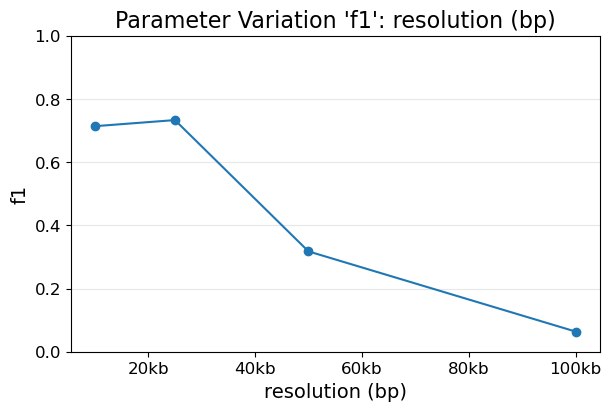

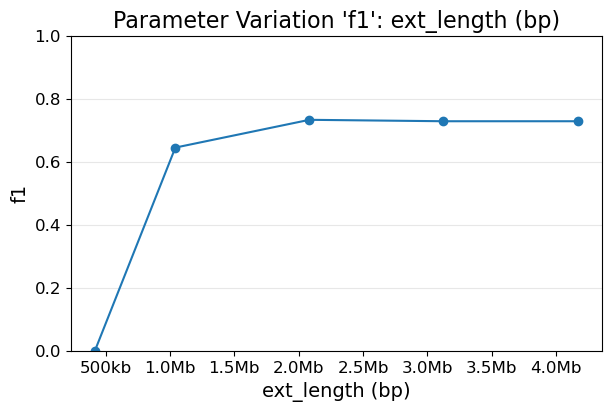

In [11]:
# %%
import matplotlib.pyplot as plt

for cfg in sweep_configs:
    name = cfg["name"]
    
    if name == "window_size":
        x = [(w - w / 6) / 2 for w in cfg["values"]]
    else:
        x = list(cfg["values"])

    y = results[name]
    x_pos = range(len(y))

    fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
    ax.plot(x, y, marker="o")

    # ax.set_xticks(list(x_pos))
    # ax.set_xticklabels(x_labels, rotation=25, ha="center", fontsize=10)
    
    # let matplotlib pick the tick locations, just format them
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda v, pos, fmt=cfg["fmt"]: fmt(v))
    )

    ax.set_xlabel(cfg["xlabel"], fontsize=14)
    ax.set_ylabel(f"{score_col}", fontsize=14)
    ax.set_title(
        f"Parameter Variation '{score_col}': {cfg['xlabel']}",
        fontsize=16
    )

    ax.tick_params(axis="both", labelsize=12)

    ax.set_ylim(0, 1)
    ax.grid(True, axis="y", alpha=0.3)

    plt.savefig(f"{analysis_dir}/param_variation_{method}_{name}_{score_col}.png", dpi=300)

    plt.show()

In [14]:
# %%
results = {}
for cfg in sweep_configs:
    scores = {"f1": [], "precision": [], "recall": []}
    for v in cfg["values"]:
        p = params_for(cfg["name"], v)
        leniency = int(p["resolution"] * 2)
        pool = compute_pooled_f1(
            hic_files=hic_files, jet_loc_files=jet_loc_files,
            fun_base=fun_base, leniency=leniency, **p,
        )
        for m in ("f1", "precision", "recall"):
            scores[m].append(pool[m])
        print(f"[{cfg['name']}={cfg['fmt'](v)}] "
              f"TP={pool['tp']} FP={pool['fp']} FN={pool['fn']} | "
              f"F1={pool['f1']:.3f}  P={pool['precision']:.3f}  R={pool['recall']:.3f}")
    results[cfg["name"]] = scores
    print()

[resolution=10kb] TP=70 FP=38 FN=21 | F1=0.704  P=0.648  R=0.769
[resolution=25kb] TP=59 FP=11 FN=32 | F1=0.733  P=0.843  R=0.648
No intersections found between predictions and true jets.
[resolution=50kb] TP=26 FP=9 FN=65 | F1=0.413  P=0.743  R=0.286
[resolution=100kb] TP=3 FP=0 FN=88 | F1=0.064  P=1.000  R=0.033

[window_size=1.0Mb] TP=0 FP=1 FN=91 | F1=0.000  P=0.000  R=0.000
No intersections found between predictions and true jets.
[window_size=2.5Mb] TP=49 FP=12 FN=42 | F1=0.645  P=0.803  R=0.538
[window_size=5.0Mb] TP=59 FP=11 FN=32 | F1=0.733  P=0.843  R=0.648
[window_size=7.5Mb] TP=59 FP=12 FN=32 | F1=0.728  P=0.831  R=0.648
[window_size=10.0Mb] TP=59 FP=12 FN=32 | F1=0.728  P=0.831  R=0.648



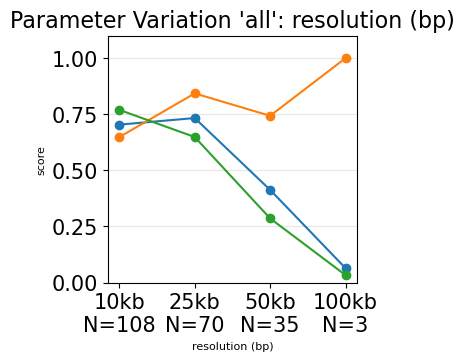

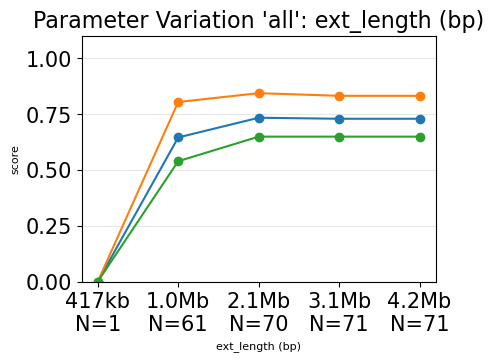

In [21]:
# %%
import matplotlib.pyplot as plt

for cfg in sweep_configs:
    name = cfg["name"]

    if name == "window_size":
        vals = [(w - w / 6) / 2 for w in cfg["values"]]
        x_labels = [f"{cfg['fmt'](v)}\nN={cfg['N_str'][i]}" for i, v in enumerate(vals)]
    else:
        x_labels = [f"{cfg['fmt'](v)}\nN={cfg['N_str'][i]}" for i, v in enumerate(cfg["values"])]

    scores = results[name]
    x_pos = range(len(x_labels))

    if name == "resolution":
        figsize = (3.5, 3.5)
    else:
        figsize = (4.5, 3.5)

    fig, ax = plt.subplots(figsize=figsize, layout="constrained")
    for m in ("f1", "precision", "recall"):
        ax.plot(x_pos, scores[m], marker="o", label=m)

    ax.set_xticks(list(x_pos))
    if name == "jet_width":
        ax.set_xticklabels(x_labels, rotation=45, ha="center", fontsize=15)
    else:
        ax.set_xticklabels(x_labels, rotation=0, ha="center", fontsize=15)

    ax.set_xlabel(cfg["xlabel"], fontsize=8)
    ax.set_ylabel("score", fontsize=8)
    ax.set_title(
        f"Parameter Variation 'all': {cfg['xlabel']}",
        fontsize=16
    )

    ax.tick_params(axis="both", labelsize=15)

    ax.set_ylim(0, 1.1)
    ax.grid(True, axis="y", alpha=0.3)
    # ax.legend(fontsize=12.5)

    plt.savefig(f"{analysis_dir}/param_variation_{method}_{name}_all.png", dpi=300)
    plt.show()

# %%